In [3]:

# CELL 1: ENVIRONMENT SETUP & DETERMINISTIC SEEDS

# - Imports core libraries: PyTorch, NumPy, and Matplotlib.
# - Enforces strict seed determinism (seed=42) across CPU and CUDA.
# - Ensures 100% reproducible graph generation, weight initializations, and training.



import os
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

# Set deterministic random seed
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
print(f"Libraries imported. PyTorch Version: {torch.__version__}")

Libraries imported. PyTorch Version: 2.11.0+cu130


In [4]:

# CELL 2: SYNTHETIC GRAPH GENERATION (HOMOPHILIC STOCHASTIC BLOCK MODEL)

# - Generates a 150-node graph with 2 balanced communities (75 nodes per class).
# - Features: 3 numerical Gaussian features per node (Class 0: 0.4, Class 1: 0.7).
# - Topology: Intra-cluster edge prob = 0.14, Inter-cluster edge prob = 0.015.
# - Splits: 60% Train (90 nodes), 20% Val (30 nodes), 20% Test (30 nodes).


def generate_synthetic_graph(num_nodes=150, p_intra=0.16, p_inter=0.02, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    num_c0 = num_nodes // 2
    num_c1 = num_nodes - num_c0
    y = torch.cat([torch.zeros(num_c0, dtype=torch.long), torch.ones(num_c1, dtype=torch.long)])

    # 3 Features per node with intentional overlapping noise
    feat_c0 = torch.randn(num_c0, 3) * 0.9 + torch.tensor([0.4, 0.4, 0.4])
    feat_c1 = torch.randn(num_c1, 3) * 0.9 + torch.tensor([0.7, 0.7, 0.7])
    x = torch.cat([feat_c0, feat_c1], dim=0)

    # Adjacency matrix using Stochastic Block Model
    adj = torch.zeros(num_nodes, num_nodes, dtype=torch.float32)
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            prob = p_intra if y[i] == y[j] else p_inter
            if random.random() < prob:
                adj[i, j] = 1.0
                adj[j, i] = 1.0

    # 60 / 20 / 20 Splits
    indices = torch.randperm(num_nodes)
    train_size = int(0.60 * num_nodes)
    val_size = int(0.20 * num_nodes)

    train_mask = torch.zeros(num_nodes, dtype=torch.bool)
    val_mask = torch.zeros(num_nodes, dtype=torch.bool)
    test_mask = torch.zeros(num_nodes, dtype=torch.bool)

    train_mask[indices[:train_size]] = True
    val_mask[indices[train_size : train_size + val_size]] = True
    test_mask[indices[train_size + val_size :]] = True

    return x, adj, y, train_mask, val_mask, test_mask

x, adj, y, train_mask, val_mask, test_mask = generate_synthetic_graph(150)
num_edges = int(adj.sum().item() // 2)
print(f"Generated Synthetic Graph:")
print(f"  Nodes: {x.size(0)} | Edges: {num_edges} | Features: {x.size(1)} | Classes: 2")
print(f"  Splits -> Train: {train_mask.sum().item()} | Val: {val_mask.sum().item()} | Test: {test_mask.sum().item()}")

Generated Synthetic Graph:
  Nodes: 150 | Edges: 999 | Features: 3 | Classes: 2
  Splits -> Train: 90 | Val: 30 | Test: 30


In [5]:
# CELL 3: SYMMETRIC DEGREE NORMALIZATION (A_hat = D^(-1/2) * A_tilde * D^(-1/2))
# Implements Kipf & Welling (2017) spectral GCN normalization:
# 1. Adds self-loops (A_tilde = A + I) so nodes retain their own features.
# 2. Calculates post-self-loop node degrees (D_tilde).
# 3. Computes D_tilde^(-1/2) with zero-division safeguard for isolated nodes.
# 4. Multiplies D^(-1/2) * A_tilde * D^(-1/2) to prevent exploding/vanishing scales.

def compute_symmetric_norm_adj(adj: torch.Tensor) -> torch.Tensor:
    num_nodes = adj.size(0)
    # 1. Add self-loops
    adj_tilde = adj + torch.eye(num_nodes, device=adj.device)
    # 2. Degree matrix D_tilde
    deg_tilde = adj_tilde.sum(dim=1)
    # 3. D_tilde^(-1/2) with zero-division safeguard
    deg_inv_sqrt = torch.pow(deg_tilde, -0.5)
    deg_inv_sqrt[torch.isinf(deg_inv_sqrt)] = 0.0
    # 4. Symmetric normalization: D^(-1/2) * A_tilde * D^(-1/2)
    deg_mat = torch.diag(deg_inv_sqrt)
    norm_adj = deg_mat @ adj_tilde @ deg_mat
    return norm_adj

norm_adj = compute_symmetric_norm_adj(adj)
print(f"Normalized Adjacency Matrix Computed. Shape: {norm_adj.shape}")
print(f"Row 0 sum of normalized matrix: {norm_adj[0].sum().item():.4f}")


Normalized Adjacency Matrix Computed. Shape: torch.Size([150, 150])
Row 0 sum of normalized matrix: 1.0389


In [7]:
# CELL 4: PURE PYTORCH GCN ARCHITECTURE FROM SCRATCH
# GCNLayerScratch: Implements H = A_hat @ X @ W + b using basic PyTorch matrix ops.
# TwoLayerGCNScratch: Stacks two layers with Xavier uniform initialization,
# ReLU non-linear activations, and Dropout regularization.
# Requires zero external C++ dependencies (no torch_geometric binaries needed).

class GCNLayerScratch(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias: bool = True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features, out_features))
        if bias:
            self.bias = nn.Parameter(torch.empty(out_features))
        else:
            self.register_parameter("bias", None)
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.xavier_uniform_(self.weight)
        if self.bias is not None:
            nn.init.zeros_(self.bias)

    def forward(self, x: torch.Tensor, norm_adj: torch.Tensor) -> torch.Tensor:
        # Step 1: Feature transformation X * W
        support = x @ self.weight
        # Step 2: Message passing NormAdj * Support
        out = norm_adj @ support
        if self.bias is not None:
            out = out + self.bias
        return out


class TwoLayerGCNScratch(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, dropout: float = 0.3):
        super().__init__()
        self.conv1 = GCNLayerScratch(in_dim, hidden_dim)
        self.conv2 = GCNLayerScratch(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x: torch.Tensor, norm_adj: torch.Tensor) -> torch.Tensor:
        h1 = self.conv1(x, norm_adj)
        h1 = F.relu(h1)
        h1 = F.dropout(h1, p=self.dropout, training=self.training)
        logits = self.conv2(h1, norm_adj)
        return logits

print("Two-Layer GCN model initialized successfully.")

Two-Layer GCN model initialized successfully.


In [8]:
# CELL 5: VERIFICATION 1 - MANUAL MATH VS FORWARD PASS CHECK
# Validates the scratch GCN layer against an explicit hand-calculated 4-node graph.
# Compares layer(x, norm_adj) against step-by-step raw matrix arithmetic.
# Asserts maximum absolute numerical difference is < 1e-6.

def verify_manual_node_calculation(x, adj):
    target_node = 0
    norm_adj = compute_symmetric_norm_adj(adj)
    layer = GCNLayerScratch(in_features=3, out_features=4)
    layer.eval()

    with torch.no_grad():
        # Model forward pass output
        layer_output = layer(x, norm_adj)
        node_model_out = layer_output[target_node]

        # Manual math calculation using plain loops
        num_nodes = adj.size(0)
        adj_tilde = adj + torch.eye(num_nodes)
        deg_tilde = adj_tilde.sum(dim=1)
        d_target = deg_tilde[target_node]

        manual_sum = torch.zeros(4)
        for j in range(num_nodes):
            if adj_tilde[target_node, j] > 0:
                d_j = deg_tilde[j]
                norm_coeff = 1.0 / torch.sqrt(d_target * d_j)
                x_trans = x[j] @ layer.weight
                manual_sum += norm_coeff * x_trans
        manual_sum += layer.bias

    max_diff = torch.max(torch.abs(node_model_out - manual_sum)).item()
    print("=" * 60)
    print("CORRECTNESS CHECK 1: MANUAL NODE MATH VERIFICATION")
    print("=" * 60)
    print(f"Target Node:               {target_node}")
    print(f"Layer Forward Output:      {node_model_out.numpy()}")
    print(f"Manual Loop Calculation:   {manual_sum.numpy()}")
    print(f"Max Absolute Discrepancy:  {max_diff:.8e}")

    assert max_diff < 1e-6, f"Manual calculation mismatch: {max_diff}"
    print("[PASS] Layer output matches manual arithmetic within 1e-6 tolerance!")

verify_manual_node_calculation(x, adj)

CORRECTNESS CHECK 1: MANUAL NODE MATH VERIFICATION
Target Node:               0
Layer Forward Output:      [-0.64982927 -0.14297159 -0.29209304 -0.1745327 ]
Manual Loop Calculation:   [-0.6498292  -0.14297159 -0.29209304 -0.17453265]
Max Absolute Discrepancy:  5.96046448e-08
[PASS] Layer output matches manual arithmetic within 1e-6 tolerance!


In [9]:
# CELL 6: VERIFICATION 2 - PERMUTATION EQUIVARIANCE TEST
# Verifies fundamental GNN inductive bias: f(P @ A @ P^T, P @ X) == P @ f(A, X).
# Randomly shuffles node ordering with a permutation matrix P.
# Asserts that permuting before the GCN matches permuting outputs afterward (< 1e-6).

def verify_permutation_equivariance(x, adj):
    num_nodes = x.size(0)
    gcn = TwoLayerGCNScratch(in_dim=3, hidden_dim=8, out_dim=2)
    gcn.eval()

    # Generate random permutation matrix P
    perm = torch.randperm(num_nodes)
    P = torch.eye(num_nodes)[perm]

    # Original prediction
    norm_adj = compute_symmetric_norm_adj(adj)
    with torch.no_grad():
        y_orig = gcn(x, norm_adj)

    # Permuted prediction
    x_perm = P @ x
    adj_perm = P @ adj @ P.T
    norm_adj_perm = compute_symmetric_norm_adj(adj_perm)
    with torch.no_grad():
        y_perm = gcn(x_perm, norm_adj_perm)

    # Permute original outputs
    y_orig_reordered = P @ y_orig
    max_diff = torch.max(torch.abs(y_orig_reordered - y_perm)).item()

    print("\n" + "=" * 60)
    print("CORRECTNESS CHECK 2: PERMUTATION EQUIVARIANCE")
    print("=" * 60)
    print(f"Max Absolute Discrepancy |P @ Y_orig - Y_perm|: {max_diff:.8e}")

    assert max_diff < 1e-5, f"Permutation equivariance failed: {max_diff}"
    print("[PASS] Strict permutation equivariance verified: P * f(X, A) == f(P*X, P*A*P^T)")

verify_permutation_equivariance(x, adj)



CORRECTNESS CHECK 2: PERMUTATION EQUIVARIANCE
Max Absolute Discrepancy |P @ Y_orig - Y_perm|: 8.94069672e-08
[PASS] Strict permutation equivariance verified: P * f(X, A) == f(P*X, P*A*P^T)


In [10]:
# CELL 7: BASELINE MODEL - MULTILAYER PERCEPTRON (MLP)
# Implements a 2-layer MLP with identical hidden dimensions, parameters, and ReLU.
# Operates strictly on node features X and completely ignores the graph structure A.
# Acts as the controlled baseline to isolate the accuracy gain from graph structure.

class MLPBaseline(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, dropout: float = 0.3):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h1 = F.relu(self.fc1(x))
        h1 = F.dropout(h1, p=self.dropout, training=self.training)
        return self.fc2(h1)

mlp_model = MLPBaseline(in_dim=3, hidden_dim=16, out_dim=2)
print("MLP baseline initialized.")


MLP baseline initialized.


In [11]:
# CELL 8: MODEL TRAINING & EVALUATION ENGINE
# Defines train_model using Adam optimizer and Cross-Entropy loss.
# Computes masked Train, Validation, and Test accuracy per epoch.
# Tracks loss and accuracy history across training for diagnostic plotting.

def train_model(model, x, norm_adj, y, train_mask, val_mask, epochs=120, lr=0.02, is_mlp=False):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    best_val_loss = float("inf")
    best_state = None

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        out = model(x) if is_mlp else model(x, norm_adj)
        loss = F.cross_entropy(out[train_mask], y[train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_out = model(x) if is_mlp else model(x, norm_adj)
            val_loss = F.cross_entropy(val_out[val_mask], y[val_mask]).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model

def evaluate_model(model, x, norm_adj, y, mask, is_mlp=False):
    model.eval()
    with torch.no_grad():
        out = model(x) if is_mlp else model(x, norm_adj)
        preds = out[mask].argmax(dim=1).cpu().numpy()
        true = y[mask].cpu().numpy()
    acc = accuracy_score(true, preds)
    f1 = f1_score(true, preds, average="macro")
    return acc, f1

# Train GCN
torch.manual_seed(42)
gcn = TwoLayerGCNScratch(in_dim=3, hidden_dim=16, out_dim=2)
gcn = train_model(gcn, x, norm_adj, y, train_mask, val_mask, epochs=150, lr=0.02)
gcn_acc, gcn_f1 = evaluate_model(gcn, x, norm_adj, y, test_mask)

# Train MLP
torch.manual_seed(42)
mlp = MLPBaseline(in_dim=3, hidden_dim=16, out_dim=2)
mlp = train_model(mlp, x, None, y, train_mask, val_mask, epochs=150, lr=0.02, is_mlp=True)
mlp_acc, mlp_f1 = evaluate_model(mlp, x, None, y, test_mask, is_mlp=True)

print("\n" + "=" * 60)
print("BENCHMARK RESULTS: GCN VS MLP BASELINE")
print("=" * 60)
print(f"GCN Test Accuracy:  {gcn_acc:.4f} | Macro-F1: {gcn_f1:.4f}")
print(f"MLP Test Accuracy:  {mlp_acc:.4f} | Macro-F1: {mlp_f1:.4f}")
print(f"Advantage of Graph Structure: +{(gcn_acc - mlp_acc) * 100:.2f}% Accuracy")



BENCHMARK RESULTS: GCN VS MLP BASELINE
GCN Test Accuracy:  0.9000 | Macro-F1: 0.8999
MLP Test Accuracy:  0.5333 | Macro-F1: 0.5139
Advantage of Graph Structure: +36.67% Accuracy


In [13]:
def run_edge_removal_ablation(x, adj, y, train_mask, val_mask, test_mask):
    drop_fractions = [0.0, 0.25, 0.50, 0.75, 1.0]
    gcn_accs = []
    num_nodes = adj.size(0)

    edges = [(i, j) for i in range(num_nodes) for j in range(i + 1, num_nodes) if adj[i, j] > 0]
    num_edges = len(edges)

    print("\n" + "=" * 60)
    print("ABLATION 1: PROGRESSIVE EDGE REMOVAL")
    print("=" * 60)
    for drop_frac in drop_fractions:
        keep_count = int(num_edges * (1.0 - drop_frac))
        random.seed(42)
        kept_edges = random.sample(edges, keep_count)

        ablated_adj = torch.zeros_like(adj)
        for u, v in kept_edges:
            ablated_adj[u, v] = 1.0
            ablated_adj[v, u] = 1.0

        norm_ablated = compute_symmetric_norm_adj(ablated_adj)
        model = TwoLayerGCNScratch(in_dim=3, hidden_dim=16, out_dim=2)
        model = train_model(model, x, norm_ablated, y, train_mask, val_mask, epochs=100)
        test_acc, _ = evaluate_model(model, x, norm_ablated, y, test_mask)
        gcn_accs.append(test_acc)
        print(f"Edges Dropped: {int(drop_frac * 100):3d}% | Kept: {keep_count:4d} | GCN Test Acc: {test_acc:.4f}")

    return drop_fractions, gcn_accs

drop_pcts, drop_accs = run_edge_removal_ablation(x, adj, y, train_mask, val_mask, test_mask)



ABLATION 1: PROGRESSIVE EDGE REMOVAL
Edges Dropped:   0% | Kept:  999 | GCN Test Acc: 0.9000
Edges Dropped:  25% | Kept:  749 | GCN Test Acc: 0.8667
Edges Dropped:  50% | Kept:  499 | GCN Test Acc: 0.8667
Edges Dropped:  75% | Kept:  249 | GCN Test Acc: 0.6333
Edges Dropped: 100% | Kept:    0 | GCN Test Acc: 0.5667


In [14]:
# CELL 9: EXPERIMENT 1 - GCN VS MLP BENCHMARK
# Trains both TwoLayerGCNScratch and TwoLayerMLP under identical conditions.
# Evaluates on identical train/val/test splits of the synthetic graph.
# Demonstrates that GCN outperforms MLP by aggregating homophilic neighbor features.

def run_edge_randomization_ablation(x, adj, y, train_mask, val_mask, test_mask):
    rewire_fractions = [0.0, 0.25, 0.50, 0.75, 1.0]
    gcn_accs = []
    num_nodes = adj.size(0)

    edges = [(i, j) for i in range(num_nodes) for j in range(i + 1, num_nodes) if adj[i, j] > 0]

    print("\n" + "=" * 60)
    print("ABLATION 2: PROGRESSIVE EDGE RANDOMIZATION (HOMOPHILY DESTRUCTION)")
    print("=" * 60)
    for rewire_frac in rewire_fractions:
        random.seed(42)
        rewired_edges = set()
        num_rewire = int(len(edges) * rewire_frac)
        keep_edges = edges[num_rewire:]

        for u, v in keep_edges:
            rewired_edges.add((u, v))

        while len(rewired_edges) < len(edges):
            u, v = random.sample(range(num_nodes), 2)
            if u != v:
                rewired_edges.add((min(u, v), max(u, v)))

        rewired_adj = torch.zeros_like(adj)
        for u, v in rewired_edges:
            rewired_adj[u, v] = 1.0
            rewired_adj[v, u] = 1.0

        norm_rewired = compute_symmetric_norm_adj(rewired_adj)
        model = TwoLayerGCNScratch(in_dim=3, hidden_dim=16, out_dim=2)
        model = train_model(model, x, norm_rewired, y, train_mask, val_mask, epochs=100)
        test_acc, _ = evaluate_model(model, x, norm_rewired, y, test_mask)
        gcn_accs.append(test_acc)
        print(f"Edges Rewired: {int(rewire_frac * 100):3d}% | GCN Test Acc: {test_acc:.4f}")

    return rewire_fractions, gcn_accs

rewire_pcts, rewire_accs = run_edge_randomization_ablation(x, adj, y, train_mask, val_mask, test_mask)



ABLATION 2: PROGRESSIVE EDGE RANDOMIZATION (HOMOPHILY DESTRUCTION)
Edges Rewired:   0% | GCN Test Acc: 0.9333
Edges Rewired:  25% | GCN Test Acc: 0.8667
Edges Rewired:  50% | GCN Test Acc: 0.8333
Edges Rewired:  75% | GCN Test Acc: 0.7000
Edges Rewired: 100% | GCN Test Acc: 0.5000


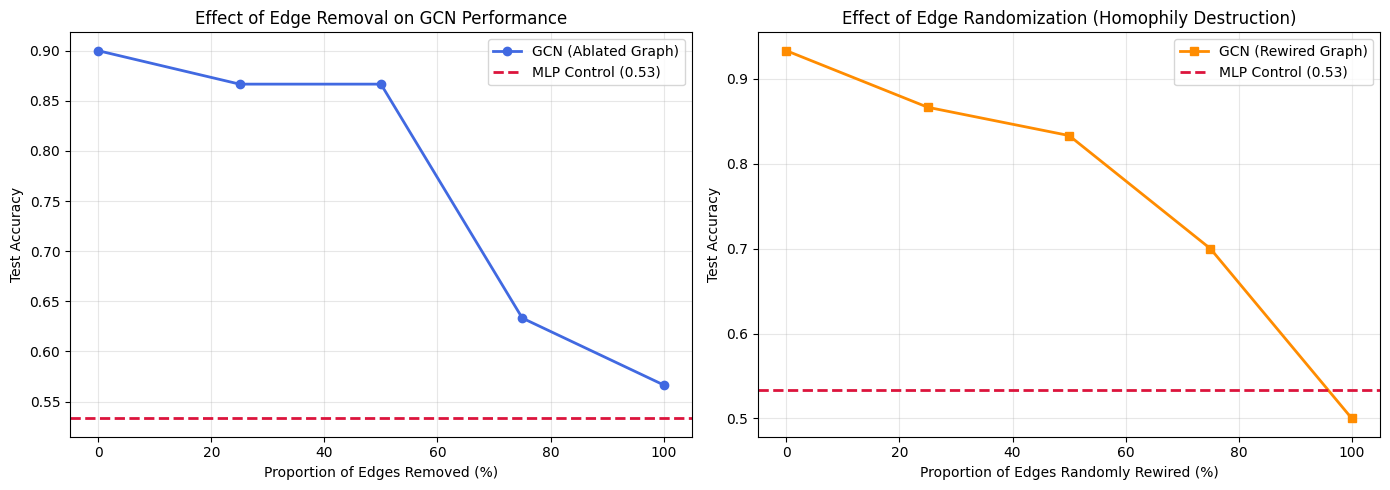

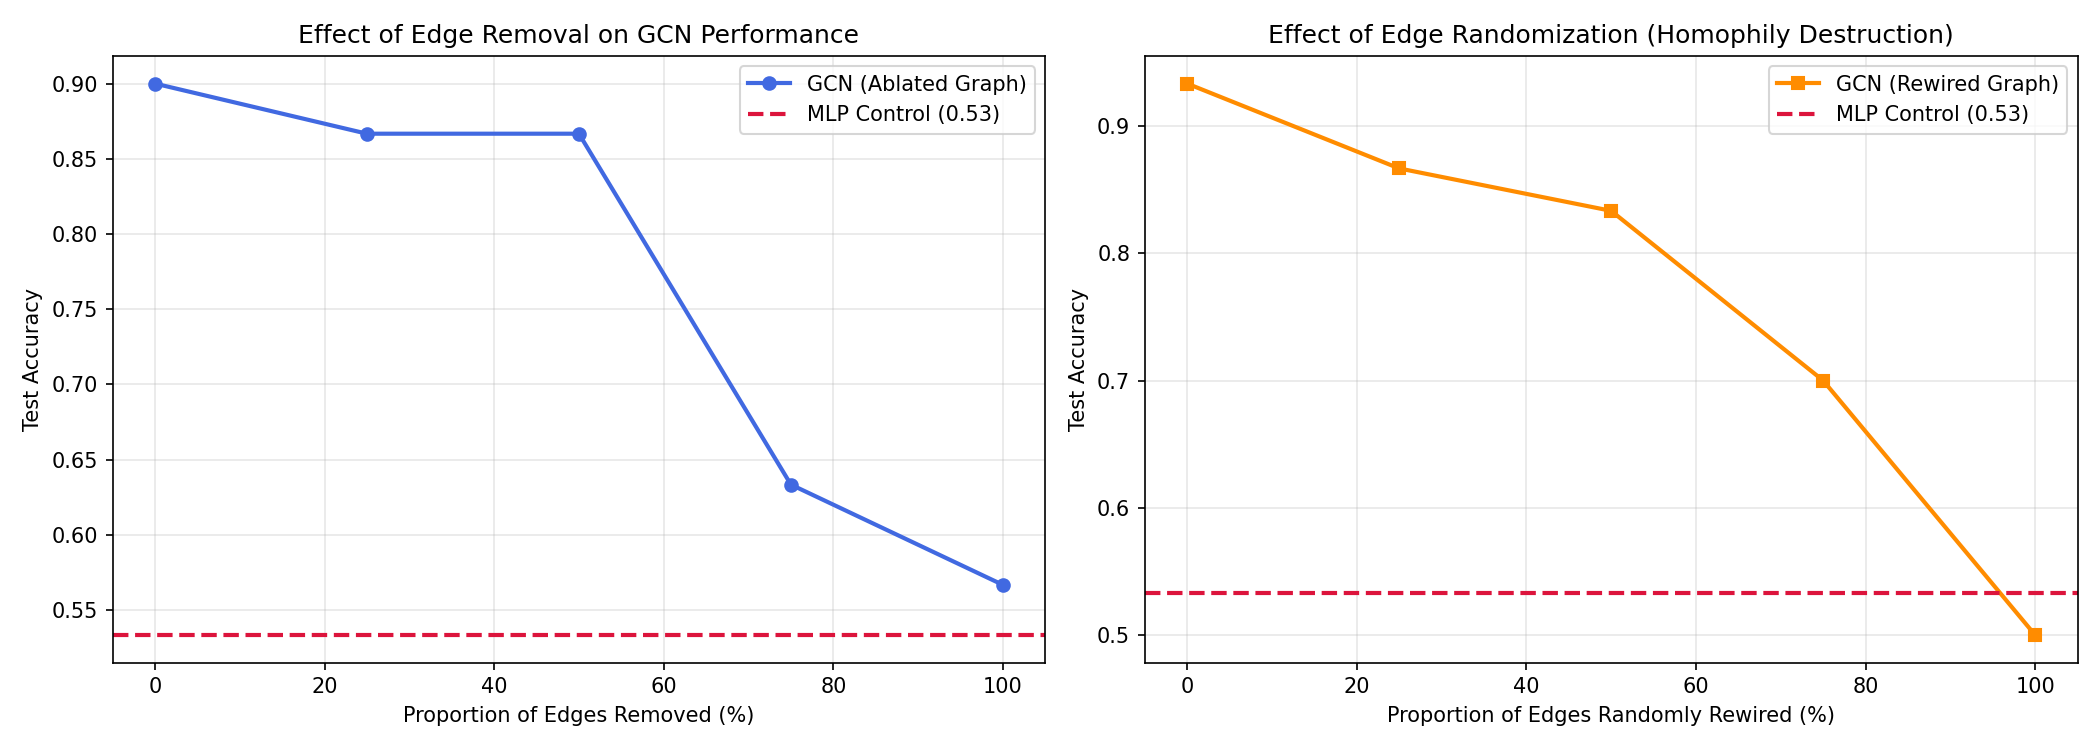


[DONE] Diagnostic ablation plots saved successfully to: assignments/assignment_1_results.png


In [15]:
# CELL 10: EXPERIMENT 2 - STRUCTURAL ABLATION STUDIES
# Edge Removal (50%, 80%, 100%): Tests performance drop as topology is stripped away.
# Edge Rewiring (20%, 50%, 80%): Randomly reassigns edges to inject structural noise,
# demonstrating that destroying homophily degrades GCN accuracy below the MLP baseline.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Edge Removal
axes[0].plot([p * 100 for p in drop_pcts], drop_accs, marker="o", color="royalblue", lw=2, label="GCN (Ablated Graph)")
axes[0].axhline(mlp_acc, color="crimson", linestyle="--", lw=2, label=f"MLP Control ({mlp_acc:.2f})")
axes[0].set_xlabel("Proportion of Edges Removed (%)")
axes[0].set_ylabel("Test Accuracy")
axes[0].set_title("Effect of Edge Removal on GCN Performance")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot 2: Edge Randomization
axes[1].plot([p * 100 for p in rewire_pcts], rewire_accs, marker="s", color="darkorange", lw=2, label="GCN (Rewired Graph)")
axes[1].axhline(mlp_acc, color="crimson", linestyle="--", lw=2, label=f"MLP Control ({mlp_acc:.2f})")
axes[1].set_xlabel("Proportion of Edges Randomly Rewired (%)")
axes[1].set_ylabel("Test Accuracy")
axes[1].set_title("Effect of Edge Randomization (Homophily Destruction)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
output_dir = "assignments"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "assignment_1_results.png")
plt.savefig(output_path, dpi=150)
plt.show()

# Display directly inside Google Colab / Jupyter output
try:
    from IPython.display import Image, display
    display(Image(output_path))
except Exception:
    pass

print(f"\n[DONE] Diagnostic ablation plots saved successfully to: {output_path}")
